# Part I — Questions 1–3: basis-function regression

**Working template: no solutions implemented.**

Scope: the four-point polynomial fit, polynomial overfitting and sinusoidal bases. Synthetic data only.

The report PDF contains the assessed answers; this notebook contains the supporting implementation and experiment outputs.


## Setup and reproducibility

Add imports, repository-relative paths and explicit seed configuration below. State the environment and seed policy. This notebook must run independently after Restart Kernel and Run All. Implement the required models directly; do not call ready-made regression or k-NN estimators.


In [247]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

## Question 1 - Linear Regression & Feature Maps

In [248]:
# Load data
data = [(1,3), (2,2), (3,0), (4,5)]
data_x = np.array([x for x, y in data])
data_y = np.array([y for x, y in data])

In [249]:
def basis_function(x, k):
    """Compute the basis function for a given degree."""
    return np.array([x**d for d in range(k)]).T

In [250]:
def apply_basis_function(data_x, k):
    """Apply the basis function to the data."""
    return basis_function(data_x, k)

We know that the solution that minimizes the squared loss is given by:

$$ \hat{w}=(X^TX)^{-1}X^TY$$

But we also know that computing the inverse of a matrix is computationally expensive.

To find $\hat{w}$, we use a system of linear equations of the form $Aw=B$, where $w$ are the weights to find. 

Let $A = X^TX$ and $B=X^TY$. We now have the following system of linear equations:
$$(X^TX)w = (X^TY)$$
Solving this system, equals finding the appropriate $\hat{w}$ that minimizes the squared error and best fits the given data.

In [251]:
def fit_polynomial_regression(data_x, data_y, k):
    """Fit a polynomial regression model to the data."""
    X = apply_basis_function(data_x, k)
    # Compute weights using numpy lstq solver
    weights = np.linalg.lstsq(X.T @ X, X.T @ data_y)[0]
    
    return weights

In [252]:
k_1_weights = fit_polynomial_regression(data_x, data_y, k=1)
k_2_weights = fit_polynomial_regression(data_x, data_y, k=2)
k_3_weights = fit_polynomial_regression(data_x, data_y, k=3)
k_4_weights = fit_polynomial_regression(data_x, data_y, k=4)

### Question 1(a) — Fitted curves

Plot the supplied four data points and all four fitted curves for basis dimensions k=1,2,3,4; include labels and a legend.


In [253]:
def plot_curves(data_x, data_y, weights_list, k_values):
    """Plot the original data and the fitted curves."""
    plt.scatter(data_x, data_y, color='black', label='Data Points')
    
    x_range = np.linspace(min(data_x-1), max(data_x+1), 100)
    
    for weights, k in zip(weights_list, k_values):
        X_range = apply_basis_function(x_range, k)
        y_range = X_range @ weights
        plt.plot(x_range, y_range, label=f'k = {k}')
    
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title('Polynomial Regression Fits')
    plt.legend()
    plt.show()

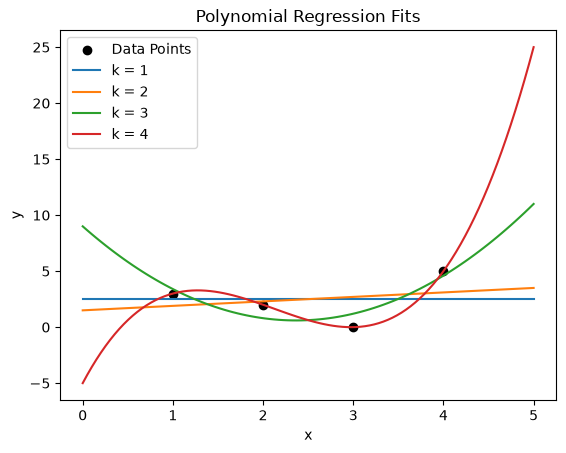

In [254]:
plot_curves(data_x, data_y, [k_1_weights, k_2_weights, k_3_weights, k_4_weights], [1, 2, 3, 4])

## Question 1(b) — Fitted equations

Report the requested fitted equations for k=1,2,3. Explain the coefficient ordering used.


In [255]:
print("K=4 Weights:", k_4_weights)


K=4 Weights: [-5.         15.16666667 -8.5         1.33333333]


In [256]:
print("K=1 equation: y = {:.2f}".format(k_1_weights[0]))

print("K=2 equation: y = {:.2f} + {:.2f}x".format(k_2_weights[0], k_2_weights[1]))

print("K=3 equation: y = {:.2f} + {:.2f}x + {:.2f}x^2".format(k_3_weights[0], k_3_weights[1], k_3_weights[2]))

print("K=4 equation: y = {:.2f} + {:.2f}x + {:.2f}x^2 + {:.2f}x^3".format(k_4_weights[0], k_4_weights[1], k_4_weights[2], k_4_weights[3]))

K=1 equation: y = 2.50
K=2 equation: y = 1.50 + 0.40x
K=3 equation: y = 9.00 + -7.10x + 1.50x^2
K=4 equation: y = -5.00 + 15.17x + -8.50x^2 + 1.33x^3


## Question 1(c) — Mean squared errors

Compute and tabulate MSE for all four fitted curves.


In [257]:
def calculate_mse(data_x, data_y, weights, k):
    """Calculate the Mean Squared Error for the fitted model."""
    X = apply_basis_function(data_x, k)
    predictions = X @ weights
    mse = np.sum((data_y - predictions) ** 2)/len(data_y)
    return mse

In [258]:
print("Means Squared Errors:")
print("K=1 MSE:", calculate_mse(data_x, data_y, k_1_weights, k=1))
print("K=2 MSE:", calculate_mse(data_x, data_y, k_2_weights, k=2))
print("K=3 MSE:", calculate_mse(data_x, data_y, k_3_weights, k=3))
print("K=4 MSE:", calculate_mse(data_x, data_y, k_4_weights, k=4))

Means Squared Errors:
K=1 MSE: 3.25
K=2 MSE: 3.05
K=3 MSE: 0.8000000000000007
K=4 MSE: 1.9428697462507256e-25


## Question 2(a)(i) — Noisy training data

Generate 30 uniform inputs on [0,1] and the specified noisy sin-squared observations with noise SD 0.07; plot the underlying function and sampled points.


## Question 2(a)(ii) — Polynomial fits

Fit dimensions k=2,5,10,14,18 and plot the curves over the data.


## Question 2(b) — Training errors

Plot natural-log training MSE against k=1,...,18. Document numerical issues if encountered.


## Question 2(c) — Test errors

Generate an independent test set of 1000 points. Plot natural-log test MSE for the training-set fits.


## Question 2(d) — Average over 100 runs

Repeat the required experiments. Plot ln(mean MSE), not mean(ln MSE). Export the required final plots.


## Question 3 — Sinusoidal bases: single run

Repeat Question 2(b,c) for basis sin(pi x),...,sin(k pi x), k=1,...,18.


## Question 3 — Sinusoidal bases: 100 runs

Repeat Question 2(d) using the sinusoidal basis; again use ln(mean MSE). Document outputs for the report.


## Final run record

Record the commit, Python/dependency versions, seeds, full protocol settings, runtime and generated figure/table filenames after the final run. Check that report results match these outputs.
